# Assignment 3: Basic Plots with Matplotlib and Seaborn

**Learning outcomes**
- Use Matplotlib and Seaborn for data visualisation.
- Create and manipulate DataFrames.
- Develop different plot types.
- Choose chart types for different questions and tell a clear story with them.

**Case study: Student attendance and performance analysis.** No dataset was supplied, so this notebook generates a realistic simulated dataset of 200 students (seeded so results are reproducible). The same code works on a real CSV: replace the simulation with `pd.read_csv("your_file.csv")`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(1)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)


## 1. Create the DataFrame

Each row is one student. Columns: attendance rate (%), monthly test scores, grade, and course.

In [2]:
n = 200
attendance = np.clip(np.random.normal(82, 10, n), 40, 100).round(1)
base = 20 + 0.6 * attendance + np.random.normal(0, 6, n)
df = pd.DataFrame({
    "student_id": range(1, n + 1),
    "grade": np.random.choice(["Year 1", "Year 2", "Year 3"], n),
    "course": np.random.choice(["Maths", "Science", "English"], n),
    "attendance_pct": attendance,
    "score": np.clip(base, 0, 100).round(1),
})
df["month"] = np.random.choice(["Jan", "Feb", "Mar", "Apr", "May", "Jun"], n)
df["passed"] = df["score"] >= 50

display(df.head())
print(df.shape)
print(df.dtypes)


,student_id,grade,course,attendance_pct,score,month,passed
0,1,Year 1,English,98.2,76.5,May,True
1,2,Year 1,Maths,75.9,70.5,Jun,True
2,3,Year 3,Maths,76.7,62.6,Jun,True
3,4,Year 3,Science,71.3,74.5,Mar,True
4,5,Year 1,Science,90.7,66.4,Apr,True


(200, 7)
student_id          int64
grade              object
course             object
attendance_pct    float64
score             float64
month              object
passed               bool
dtype: object


## 2. Manipulate the DataFrame

Filter, group and create new columns before plotting.

In [3]:
df["attendance_band"] = pd.cut(df["attendance_pct"], bins=[0, 70, 85, 100],
                               labels=["Low (<70%)", "Medium (70–85%)", "High (>85%)"])
summary = df.groupby("attendance_band", observed=True)["score"].agg(["count", "mean"]).round(1)
display(summary)

high_attenders = df[df["attendance_pct"] > 85]
print("Pass rate, high attendance:", round(high_attenders["passed"].mean() * 100, 1), "%")


,count,mean
attendance_band,,
Low (<70%),15,59.3
Medium (70–85%),101,67.6
High (>85%),84,74.2


Pass rate, high attendance: 100.0 %


## 3. Line plot: average score by month

Line plots show change over time.

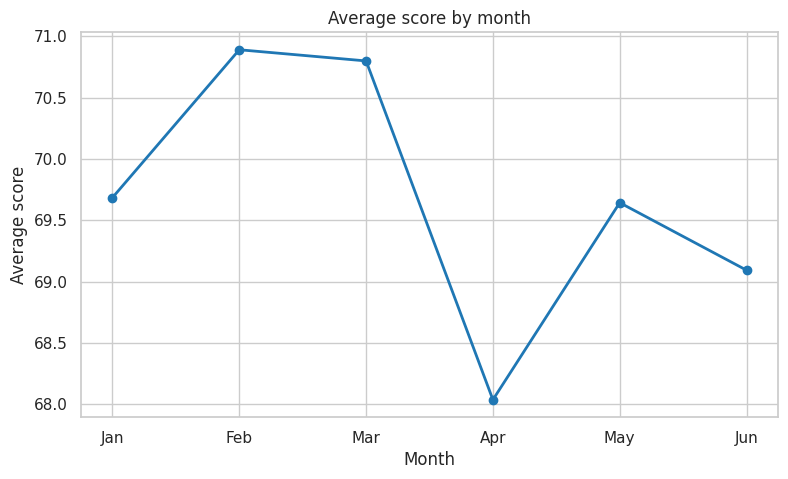

In [4]:
order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
monthly = df.groupby("month")["score"].mean().reindex(order)

fig, ax = plt.subplots()
ax.plot(order, monthly.values, marker="o", lw=2, color="tab:blue")
ax.set_title("Average score by month")
ax.set_xlabel("Month")
ax.set_ylabel("Average score")
plt.show()


## 4. Bar plot: average score by grade and course

Bar charts compare categories. Seaborn's `barplot` shows the mean and a 95% confidence interval.

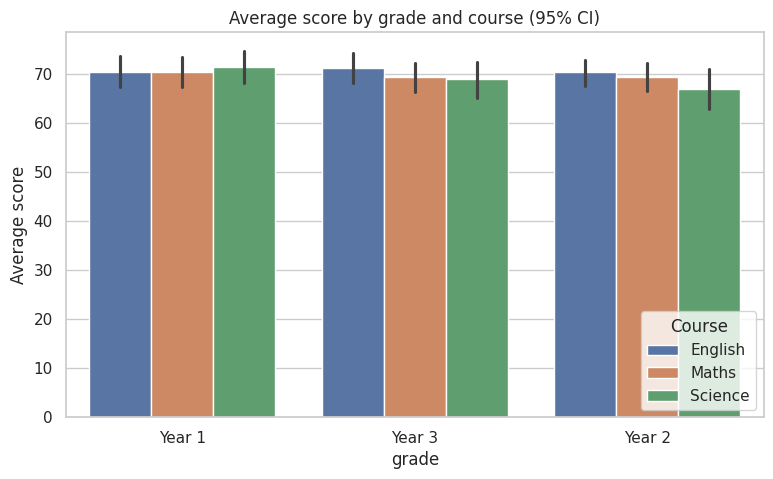

In [5]:
fig, ax = plt.subplots()
sns.barplot(data=df, x="grade", y="score", hue="course", ax=ax, errorbar=("ci", 95))
ax.set_title("Average score by grade and course (95% CI)")
ax.set_ylabel("Average score")
plt.legend(title="Course", loc="lower right")
plt.show()


## 5. Histogram with density curve: score distribution

Histograms show the shape of one variable.

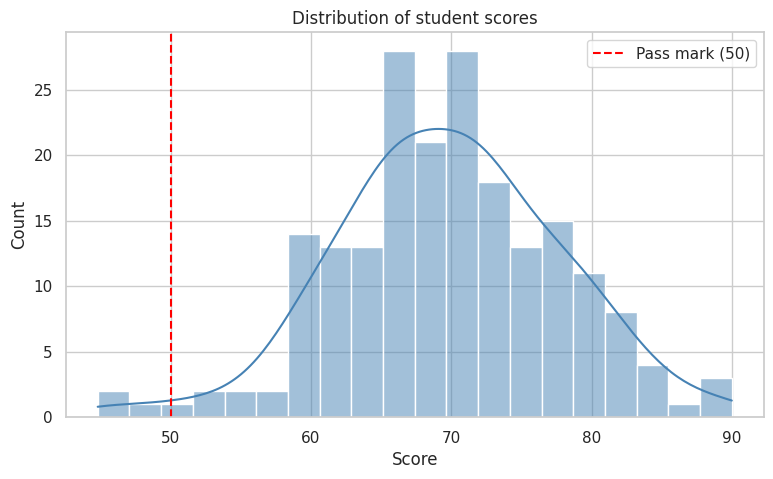

In [6]:
fig, ax = plt.subplots()
sns.histplot(df["score"], bins=20, kde=True, color="steelblue", ax=ax)
ax.axvline(50, color="red", ls="--", label="Pass mark (50)")
ax.set_title("Distribution of student scores")
ax.set_xlabel("Score")
ax.legend()
plt.show()


## 6. Scatter plot with regression: attendance vs score

Scatter plots show the relationship between two numeric variables. Remember that correlation does not prove cause.

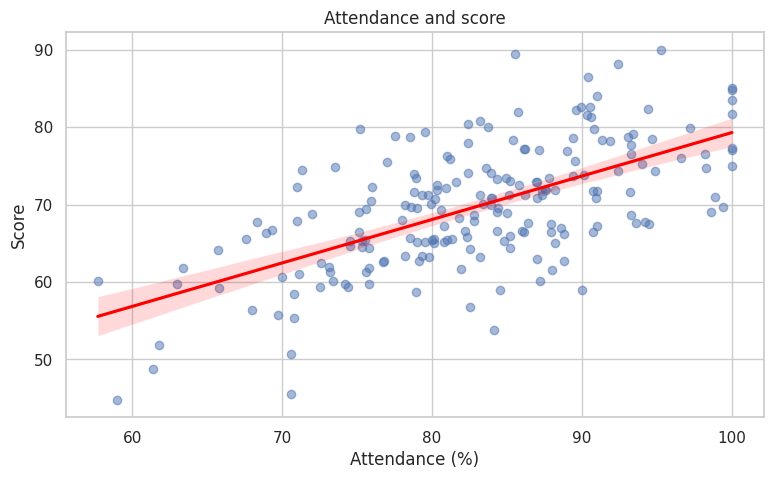

Correlation (Pearson r): 0.62


In [7]:
fig, ax = plt.subplots()
sns.regplot(data=df, x="attendance_pct", y="score", scatter_kws={"alpha": 0.5}, line_kws={"color": "red"}, ax=ax)
ax.set_title("Attendance and score")
ax.set_xlabel("Attendance (%)")
ax.set_ylabel("Score")
plt.show()

r = df["attendance_pct"].corr(df["score"])
print(f"Correlation (Pearson r): {r:.2f}")


## 7. Box plot: score spread by course

Box plots show the median, quartiles and outliers, which makes them good for comparing groups.

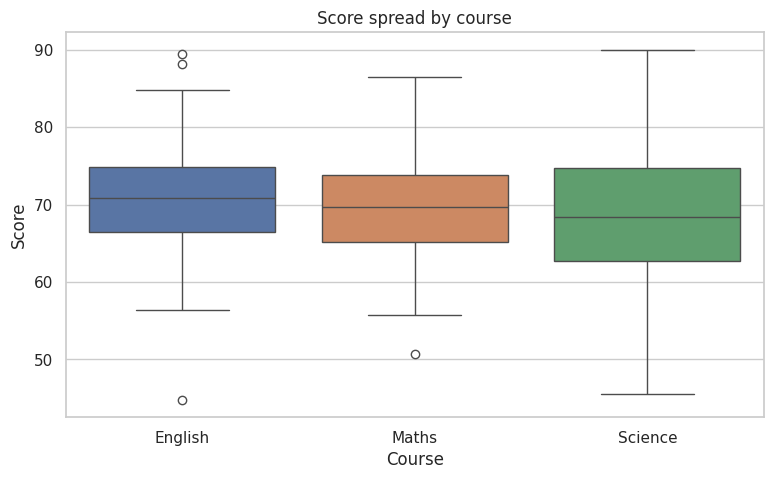

In [8]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="course", y="score", hue="course", legend=False, ax=ax)
ax.set_title("Score spread by course")
ax.set_xlabel("Course")
ax.set_ylabel("Score")
plt.show()


## 8. Heatmap: correlation between numeric variables

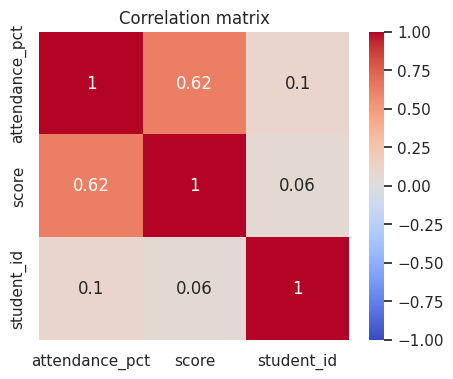

In [9]:
corr = df[["attendance_pct", "score"]].assign(
    student_id=df["student_id"]).corr().round(2)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix")
plt.show()


## 9. Choosing a chart type

| Question | Good chart | Avoid |
|---|---|---|
| How does a value change over time? | Line plot | Pie chart |
| How do categories compare? | Bar plot | 3D bars |
| What is the shape of one variable? | Histogram, box plot | Bar chart of raw values |
| Is there a relationship between two variables? | Scatter plot | Dual-axis line chart |
| How strong are many relationships? | Heatmap | Many separate charts |

**Storytelling:** Give each chart a title that states the finding (for example, "Students with high attendance score about 15 points higher"), label the axes, and remove clutter.

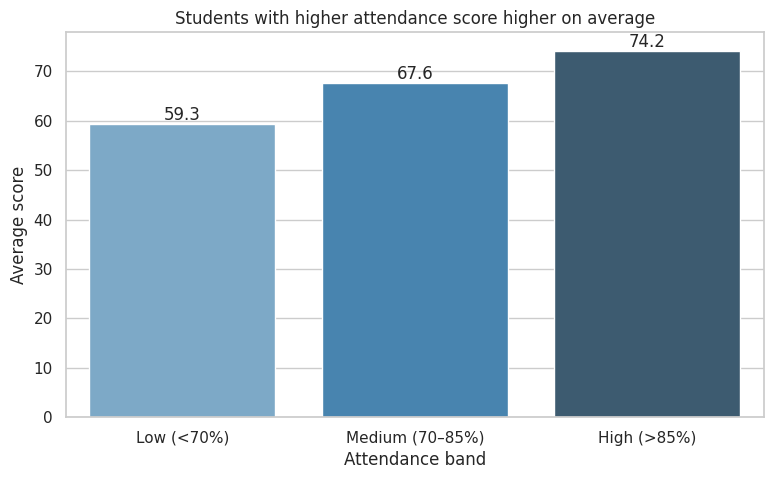

In [10]:
# A final, story-driven chart combining the key finding
fig, ax = plt.subplots()
sns.barplot(data=df.groupby("attendance_band", observed=True)["score"].mean().reset_index(),
            x="attendance_band", y="score", hue="attendance_band", legend=False, ax=ax, palette="Blues_d")
ax.set_title("Students with higher attendance score higher on average")
ax.set_xlabel("Attendance band")
ax.set_ylabel("Average score")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f")
plt.show()
